# UCR-MFG: Implementation
**Uncertainty-Conditioned Relational Routing over a Multi-Scale Fuzzy Graph for drone object detection (UAVDT)**

This notebook documents the complete implementation used for the paper. It shows the configuration, the source code
of every model component and loss, and runs the trained final model (`models/stage4_ep100_final.pth`) on a UAVDT test
frame to show what each component produces.

| Part | Component | File |
|---|---|---|
| Backbone | ResNet-50 + FPN (P3–P5) | `src/models/backbone.py` |
| C1 | Pre-graph uncertainty head (aleatoric $U_a$, epistemic $U_e$ via MC dropout) | `src/models/uncertainty_head.py` |
| Graph | Multi-scale fuzzy candidate graph (local, kNN, cross-scale; Student-t affinity) | `src/models/graph_builder.py` |
| C2 | Uncertainty-conditioned router (typed top-K, uncertainty-scaled budget) | `src/models/router.py` |
| C3 | Benefit-aware message passing (attention, benefit gate, GRU) | `src/models/message_passing.py` |
| C4 | Residual uncertainty-aware fusion gate $Z=F+(1-\lambda)\odot H$ | `src/models/fusion.py` |
| Head | Probabilistic FCOS head (cls, ltrb, centerness, log-variance) | `src/models/detection_head.py` |
| Full model | Staged UCR-MFG detector | `src/models/ucr_mfg.py` |
| Losses | Detection, β-NLL uncertainty, graph, router, consistency, total | `src/losses/` |
| Training | 4-stage curriculum, safeguards, resume | `scripts/train.py` |

## 1. Setup

In [14]:
import os, sys, json, time, inspect, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT); sys.path.insert(0, os.path.join(ROOT, "scripts"))
import numpy as np, torch, yaml
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

def show_table(headers, rows, title=None):
    """Plain-text table (no pandas needed)."""
    cells = [[str(h) for h in headers]] + [[str(v) for v in r] for r in rows]
    w = [max(len(r[i]) for r in cells) for i in range(len(headers))]
    if title:
        print(title)
    for k, r in enumerate(cells):
        print("  ".join(v.rjust(w[i]) if i else v.ljust(w[i]) for i, v in enumerate(r)))
        if k == 0:
            print("  ".join("-" * x for x in w))

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("project root:", ROOT)
print("torch", torch.__version__, "| device:", device)

project root: /Users/rahulmahaseth/Desktop/ucr_mfg
torch 2.15.0 | device: mps


## 2. Configuration of the final model
The final model was trained with `configs/experiments/uavdt_stage4_residual.yaml` (stage 4) on top of `configs/experiments/uavdt_primary.yaml` (stages 1–3), using the model settings in `configs/model/residual.yaml`.

In [15]:
exp = yaml.safe_load(open("configs/experiments/uavdt_stage4_residual.yaml"))
mcfg = yaml.safe_load(open("configs/model/residual.yaml"))
t = exp["train"]
show_table(["setting", "value"], [
    ["dataset", "UAVDT (" + yaml.safe_load(open(exp["dataset_config"]))["dataset_name"] + "), classes car / truck / bus"],
    ["input canvas (H, W)", t["img_size"]], ["training frames", f"every {t['frame_stride']}th frame -> 813 images"],
    ["epochs / batch / accumulation", f"{t['max_epochs']} / {t['batch_size']} / {t['accumulate_grad_batches']}"],
    ["optimizer / lr / weight decay", f"{t['optimizer']} / {t['lr']} / {t['weight_decay']}"],
    ["schedule", t["scheduler"]], ["initialisation", t["init_weights"]],
], "Training")
print()
m = mcfg["model"]; l = mcfg["loss"]
show_table(["setting", "value"], [
    ["backbone / FPN channels / strides", f"{m['backbone']} / {m['fpn_channels']} / {m['strides']}"],
    ["MC dropout passes T / p", f"{m['uncertainty']['mc_passes']} / {m['uncertainty']['dropout_rate']}"],
    ["graph: r_local / k_feat / alpha", f"{m['graph']['r_local']} / {m['graph']['k_feat']} / {m['graph']['alpha']}"],
    ["router budgets local/kNN/cross, k_gain", f"{m['router']['k_local']}/{m['router']['k_feat']}/{m['router']['k_cross']}, {m['router']['k_gain']}"],
    ["fusion mode / stage-3 residual", f"{m['fusion']['mode']} / {m['fusion']['stage3_residual']}"],
    ["loss weights u / var / graph / inst / benefit / cons",
     f"{l['lambda_u']} / {l['lambda_var']} / {l['lambda_graph']} / {l['lambda_inst']} / {l['lambda_benefit']} / {l['lambda_consistency']}"],
], "Model and loss")
print()
show_table(["stage", "epochs", "modules switched on", "losses"],
           [[k, f"{v['epochs'][0]}-{v['epochs'][1]}", ", ".join(v["active_modules"]), ", ".join(v["losses"])] for k, v in t["stages"].items()],
           "Training curriculum")

Training
setting                                                           value
-----------------------------  ----------------------------------------
dataset                        UAVDT (UAVDT), classes car / truck / bus
input canvas (H, W)                                         [544, 1024]
training frames                          every 30th frame -> 813 images
epochs / batch / accumulation                               100 / 2 / 2
optimizer / lr / weight decay                   AdamW / 0.0001 / 0.0001
schedule                                              CosineAnnealingLR
initialisation                                                coco_fcos

Model and loss
setting                                                                           value
----------------------------------------------------  ---------------------------------
backbone / FPN channels / strides                          resnet50 / 256 / [8, 16, 32]
MC dropout passes T / p                                        

## 3. Source code of the model
The cells below print the full source of every model file, so the notebook contains the complete implementation.

In [16]:
def show_file(path):
    src = open(path).read()
    print(f"# ===== {path} ({len(src.splitlines())} lines) =====")
    print(src)

for f in ["src/models/backbone.py", "src/models/uncertainty_head.py"]:
    show_file(f)

# ===== src/models/backbone.py (90 lines) =====
from typing import Tuple, List
import torch
import torch.nn as nn
import torchvision.models as models


class ResNetFPNBackbone(nn.Module):
    """ResNet-50 backbone with Feature Pyramid Network (FPN).
    
    Generates feature maps P3, P4, P5 with strides 8, 16, 32 and uniform channels C = 256.
    """

    def __init__(self, pretrained: bool = False, out_channels: int = 256, freeze_bn: bool = True, frozen_stages: int = 1):
        super().__init__()
        # Detection batches are tiny (2 images), so BatchNorm statistics are kept frozen at their pretrained values
        # (standard torchvision/detectron practice). frozen_stages=1 also freezes the stem + layer1 weights.
        self.freeze_bn = freeze_bn
        self.frozen_stages = frozen_stages
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        resnet = models.resnet50(weights=weights)

        # Stage 0 & 1 (stride 4)
        self.conv1 = resnet.conv1


### Multi-scale fuzzy graph and graph containers

In [17]:
for f in ["src/models/graph_ops.py", "src/models/graph_builder.py"]:
    show_file(f)

# ===== src/models/graph_ops.py (63 lines) =====
from dataclasses import dataclass
from typing import List, Sequence, Tuple

import torch

LOCAL, KNN, TOP_DOWN, BOTTOM_UP = 0, 1, 2, 3
NUM_EDGE_TYPES = 4


@dataclass
class Graph:
    """Batched candidate graph. Edges are (receiver, sender) pairs over `batch_size * num_nodes` nodes."""

    nodes: torch.Tensor
    edge_index: torch.Tensor
    edge_types: torch.Tensor
    edge_geom: torch.Tensor
    kij: torch.Tensor
    wij: torch.Tensor
    positions: torch.Tensor
    shapes: List[Tuple[int, int]]
    batch_size: int

    @property
    def num_nodes(self) -> int:
        return self.positions.shape[0]


@dataclass
class Routing:
    scores: torch.Tensor
    mask: torch.Tensor
    selected: torch.Tensor


def segment_softmax(
    logits: torch.Tensor, index: torch.Tensor, size: int, weight: torch.Tensor = None, eps: float = 1e-12
) -> torch.Tensor:
    logits = logits.float()
    seg_max = torch.full((size,), -torch.inf, device=logits.de

### C2 router, C3 message passing, C4 fusion gate

In [18]:
for f in ["src/models/router.py", "src/models/message_passing.py", "src/models/fusion.py"]:
    show_file(f)

# ===== src/models/router.py (87 lines) =====
from typing import Sequence

import torch
import torch.nn as nn

from src.models.graph_ops import NUM_EDGE_TYPES, Graph, Routing


class UCRouter(nn.Module):
    """C2: Uncertainty-conditioned relational routing.

    Each candidate edge is scored from a 140-d descriptor [h_i, h_j, k_ij, Ua_i, Ue_i, Ua_j, Ue_j, geometry, type].
    The first layer is factorised over receiver, sender and edge terms, which is exact and avoids
    materialising the descriptor. A per-receiver, per-type top-K keeps the best edges; the budget grows
    with receiver uncertainty so ambiguous locations gather more context. Straight-through masks keep
    the selection differentiable.
    """

    def __init__(
        self,
        node_dim: int = 64,
        hidden_dim: int = 64,
        budgets: Sequence[int] = (4, 2, 2, 2),
        k_gain: float = 2.0,
        use_uncertainty: bool = True,
        enabled: bool = True,
        type_dim: int = 4,
    ):
        s

### Detection head, full model and post-processing

In [19]:
for f in ["src/models/detection_head.py", "src/models/ucr_mfg.py", "src/models/postprocess.py"]:
    show_file(f)

# ===== src/models/detection_head.py (186 lines) =====
import math
from typing import List, Tuple, Dict, Any
import torch
import torch.nn as nn
import torch.nn.functional as F


class FCOSHead(nn.Module):
    """Probabilistic anchor-free FCOS head: class logits, stride-normalised ltrb distances, centerness
    and a per-side box log-variance for the aleatoric localisation uncertainty of each detection."""

    def __init__(
        self,
        in_channels: int = 256,
        num_classes: int = 10,
        strides: List[int] = [8, 16, 32],
        center_sampling_radius: float = 1.5
    ):
        super().__init__()
        self.num_classes = num_classes
        self.strides = strides
        self.center_radius = center_sampling_radius
        self.scale_limits = [[0, 64], [64, 128], [128, float("inf")]]
        self.cls_tower = self._tower(in_channels)
        self.reg_tower = self._tower(in_channels)
        self.cls_pred = nn.Conv2d(in_channels, num_classes, kernel_size=3, padding=

## 4. Source code of the losses
$\mathcal{L}=\mathcal{L}_{det}+\lambda_v\mathcal{L}_{var}+\lambda_u\mathcal{L}_u+\lambda_g\mathcal{L}_{graph}+\lambda_i\mathcal{L}_{inst}+\lambda_b\mathcal{L}_{ben}+\lambda_c\mathcal{L}_{cons}$, each term active from its curriculum stage.

In [20]:
for f in ["src/losses/detection_loss.py", "src/losses/uncertainty_loss.py", "src/losses/graph_loss.py",
          "src/losses/router_loss.py", "src/losses/consistency_loss.py", "src/losses/total_loss.py"]:
    show_file(f)

# ===== src/losses/detection_loss.py (146 lines) =====
from typing import List, Tuple, Dict, Any
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.losses.uncertainty_loss import gaussian_nll


def focal_loss(
    logits: torch.Tensor,
    targets: torch.Tensor,
    gamma: float = 2.0,
    alpha: float = 0.25
) -> torch.Tensor:
    """Sigmoid focal loss on classification logits."""
    # logits: [N, C], targets: [N] (0..C-1 for classes, C for background, -1 for ignore)
    valid_mask = targets >= 0
    if not valid_mask.any():
        return torch.tensor(0.0, device=logits.device, requires_grad=True)

    logits = logits[valid_mask]
    targets = targets[valid_mask]
    num_classes = logits.shape[1]

    # One-hot encoding (background class C becomes all zeros)
    target_one_hot = torch.zeros_like(logits)
    fg_mask = targets < num_classes
    target_one_hot[fg_mask, targets[fg_mask]] = 1.0

    p = torch.sigmoid(logits)
    ce_loss = F.binary_cross_entropy_

## 5. Load the trained final model

In [21]:
from src.evaluation import load_trained_model
model, meta = load_trained_model("models/stage4_ep100_final.pth", device)
model.eval()
print(f"epoch {meta['epoch']}, curriculum stage {model.stage}, fusion mode: {model.fusion_gate.mode}")
groups = {"backbone (ResNet-50 + FPN)": model.backbone, "C1 uncertainty head": model.unc_head,
          "graph builder": model.graph_builder, "C2 router": model.router, "C3 message passing": model.mpnn,
          "C4 fusion gate": model.fusion_gate, "FCOS head": model.det_head}
rows = [[k, f"{sum(p.numel() for p in v.parameters()):,}"] for k, v in groups.items()]
rows.append(["total", f"{sum(p.numel() for p in model.parameters()):,}"])
show_table(["module", "parameters"], rows, "Parameters per module")

epoch 100, curriculum stage 4, fusion mode: residual
Parameters per module
module                      parameters
--------------------------  ----------
backbone (ResNet-50 + FPN)  26,196,544
C1 uncertainty head          1,183,240
graph builder                   16,576
C2 router                        9,105
C3 message passing              50,693
C4 fusion gate                 198,144
FCOS head                    4,752,399
total                       32,406,701


## 6. Forward pass on one UAVDT test frame
Run the model once and inspect what each component produces.

In [22]:
from src.data.uavdt import UAVDTDataset
from src.models.uncertainty_head import mc_generator
ds = UAVDTDataset("dataset/UAVDT-Benchmark-M", "test", (544, 1024), is_train=False, frame_stride=1)
idx = [i for i, (s, _, n) in enumerate(ds.frames) if s == "M0403" and n == 169][0]
sample = ds[idx]
x = sample["image"].unsqueeze(0).to(device)
t0 = time.time()
with torch.no_grad():
    out = model(x, generator=mc_generator(0, 0, 0, device))
print(f"frame {sample['image_id']}: input {tuple(x.shape)}, {len(sample['boxes'])} annotated vehicles, "
      f"forward pass {time.time() - t0:.2f} s on {device}")
feats = model.backbone(x)
show_table(["level", "stride", "feature map", "Ua mean", "Ua max", "Ue mean", "Ue max"],
           [[f"P{l+3}", s, tuple(f.shape), f"{ua.mean():.3f}", f"{ua.max():.3f}", f"{ue.mean():.4f}", f"{ue.max():.4f}"]
            for l, (s, f, ua, ue) in enumerate(zip(model.strides, feats, out["u_a"], out["u_e"]))],
           "Backbone features and C1 uncertainty maps")

frame M0403_img000169: input (1, 3, 544, 1024), 63 annotated vehicles, forward pass 0.39 s on mps
Backbone features and C1 uncertainty maps
level  stride        feature map  Ua mean  Ua max  Ue mean  Ue max
-----  ------  -----------------  -------  ------  -------  ------
P3          8  (1, 256, 68, 128)    0.309   0.660   0.0034  0.0546
P4         16   (1, 256, 34, 64)    0.292   0.618   0.0052  0.0622
P5         32   (1, 256, 17, 32)    0.305   0.597   0.0097  0.0451


In [23]:
from src.models.graph_ops import LOCAL, KNN, TOP_DOWN, BOTTOM_UP
g, r = out["graph"], out["routing"]
names = {LOCAL: "local", KNN: "kNN", TOP_DOWN: "cross-scale (top-down)", BOTTOM_UP: "cross-scale (bottom-up)"}
sel = r.selected
rows = []
for t_id, name in names.items():
    cand = int((g.edge_types == t_id).sum()); kept = int((g.edge_types[sel] == t_id).sum())
    rows.append([name, f"{cand:,}", f"{kept:,}", f"{100 * kept / max(cand, 1):.1f}%"])
n_sel = int(sel.sum()) if sel.dtype == torch.bool else int(sel.numel())   # `selected` is a boolean mask over all edges
rows.append(["all", f"{g.edge_index.shape[1]:,}", f"{n_sel:,}", f"{100 * n_sel / g.edge_index.shape[1]:.1f}%"])
show_table(["edge type", "candidate edges", "routed edges", "kept"], rows,
           f"Fuzzy graph ({g.num_nodes:,} nodes) and C2 routing")
recv = g.edge_index[0, sel]
deg = torch.bincount(recv, minlength=g.num_nodes).float().cpu()
ua_flat = torch.cat([u.flatten() for u in out["u_a"]]).cpu(); ue_flat = torch.cat([u.flatten() for u in out["u_e"]]).cpu()
u = torch.maximum(ua_flat, ue_flat)
q = u.quantile(torch.tensor([0.5, 0.9]))
print(f"\nrouted edges per node: mean {deg.mean():.2f}; nodes with U below median {deg[u <= q[0]].mean():.2f}, "
      f"top-10% U {deg[u >= q[1]].mean():.2f}  (budget grows with uncertainty)")

Fuzzy graph (11,424 nodes) and C2 routing
edge type                candidate edges  routed edges    kept
-----------------------  ---------------  ------------  ------
local                            263,994        52,308   19.8%
kNN                               48,752        26,704   54.8%
cross-scale (top-down)            10,880        10,880  100.0%
cross-scale (bottom-up)           10,880         6,985   64.2%
all                              334,506        96,877   29.0%

routed edges per node: mean 8.48; nodes with U below median 7.69, top-10% U 8.91  (budget grows with uncertainty)


In [24]:
from src.engine import LocationCache
from src.models.postprocess import postprocess
with torch.no_grad():
    det = postprocess(out, LocationCache(model.det_head)(out["head"]["cls"]), model.strides, x.shape[-2:], **meta["inference"])[0]
det = {k: v.cpu().numpy() for k, v in det.items()}
keep = det["scores"] >= 0.3
names_c = ("car", "truck", "bus")
print(f"{int(keep.sum())} detections with score >= 0.3 (ground truth: {len(sample['boxes'])} vehicles)")
show_table(["#", "class", "score", "box (x1,y1,x2,y2)", "box std (px)", "Ua", "Ue"],
           [[i, names_c[int(det['labels'][i])], f"{det['scores'][i]:.2f}", tuple(int(v) for v in det['boxes'][i]),
             f"{det['box_std'][i].mean():.1f}", f"{det['u_a'][i]:.3f}", f"{det['u_e'][i]:.4f}"]
            for i in np.where(keep)[0][:12]], "First 12 detections: every detection carries a box std, Ua and Ue")

67 detections with score >= 0.3 (ground truth: 63 vehicles)
First 12 detections: every detection carries a box std, Ua and Ue
#   class  score     box (x1,y1,x2,y2)  box std (px)     Ua      Ue
--  -----  -----  --------------------  ------------  -----  ------
0     car   0.94  (616, 242, 640, 278)           0.6  0.000  0.0000
1     bus   0.94  (648, 220, 684, 317)           1.2  0.000  0.0000
2     car   0.94  (591, 282, 615, 319)           0.6  0.000  0.0000
3     car   0.93  (494, 366, 524, 411)           0.5  0.000  0.0000
4     car   0.93  (474, 437, 511, 496)           0.7  0.000  0.0000
5     car   0.92  (135, 216, 183, 240)           0.6  0.000  0.0000
6     car   0.91  (896, 169, 938, 188)           0.9  0.001  0.0000
7     car   0.90  (277, 176, 325, 201)           0.8  0.000  0.0000
8     car   0.90  (844, 150, 887, 174)           0.8  0.000  0.0000
9     car   0.90  (289, 253, 333, 284)           0.7  0.000  0.0000
10    car   0.90  (397, 421, 436, 482)           0.9  0.00

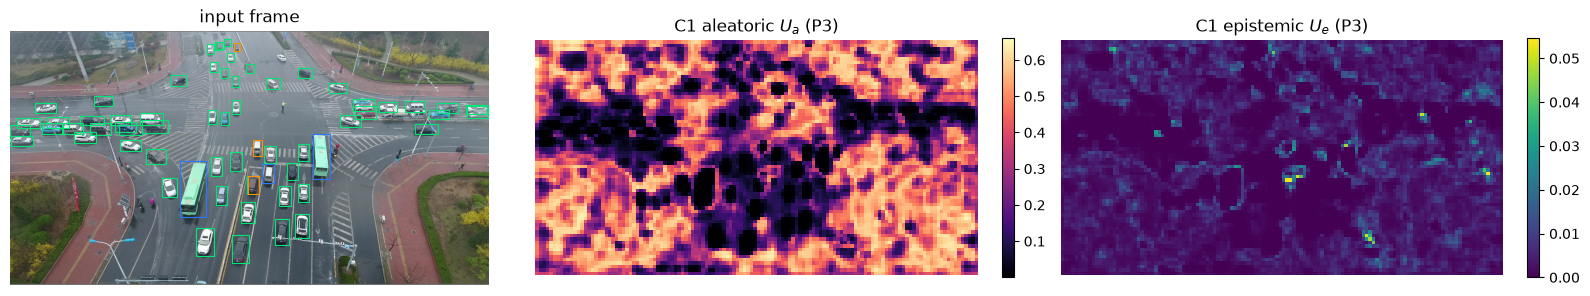

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
img = sample["image"].permute(1, 2, 0).numpy()
axes[0].imshow(img); axes[0].set_title("input frame")
for b, l, s in zip(det["boxes"][keep], det["labels"][keep], det["scores"][keep]):
    axes[0].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                                    ec=("#00e676", "#ff9100", "#2979ff")[int(l)], lw=0.8))
im1 = axes[1].imshow(out["u_a"][0][0, 0].cpu(), cmap="magma"); axes[1].set_title("C1 aleatoric $U_a$ (P3)")
im2 = axes[2].imshow(out["u_e"][0][0, 0].cpu(), cmap="viridis"); axes[2].set_title("C1 epistemic $U_e$ (P3)")
plt.colorbar(im1, ax=axes[1], fraction=0.025); plt.colorbar(im2, ax=axes[2], fraction=0.025)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Training entry point
`scripts/train.py` implements the curriculum, the loss-spike and gradient guards, the stage guard and exact resume. Training commands:
```bash
python scripts/train.py --config configs/experiments/uavdt_primary.yaml
python scripts/train.py --config configs/experiments/uavdt_stage4_residual.yaml --resume saved_models/uavdt_ep54_before_collapse.pth
```

In [26]:
show_file("scripts/train.py")

# ===== scripts/train.py (502 lines) =====
import os
import sys

os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.0")
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..")))

import argparse
import json
import random
import time
from contextlib import nullcontext

import numpy as np

import torch
import yaml
from torch.utils.data import DataLoader, Subset

from src.data.collate import collate_fn
from src.data.resumable import ResumableEpochSampler, SeededDataset
from src.data.uavdt import UAVDTDataset
from src.data.visdrone import VisDroneDataset
from src.engine import LocationCache, assign_targets, evaluate, measure_benefit
from src.losses.total_loss import UCRMFGCombinedLoss
from src.models.uncertainty_head import mc_generator
from src.models.ucr_mfg import UCRMFG
from src.utils.checkpoint import (
    GracefulInterruptHandler,
    create_checkpoint_payload,
    load_checkpoint,
    purge_old_checkpoints,
    save_atomic,
)
from src.utils.progre